In [2]:
import os, sys

# Make the ecCodes DLL findable (must run BEFORE importing xarray/cfgrib)
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

import xarray as xr
import cfgrib
import snotelpy as sp
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

1) Load the datasets
    - Forecast
    - snotel

In [ ]:
fname = '986f437998cb2c67bd913875435801ff.grib'
INDEX_PATH = '986f437998cb2c67bd913875435801ff.grib.5b7b6.idx'


DAYS_OUT = "14 Days"

#snotel observations
#HUC = 140100
snotel_station = ['842:CO:SNTL']
elements = ['WTEQ'] #snow water equivalent

START_DATE='2021-12-16' #snotel date range
END_DATE='2022-01-31'




In [4]:


# The file mixes 6-hourly fields (u10, v10, tp) and 24-hourly snowfall (sf),
# so open_datasets returns a list with one Dataset per compatible group
dss = cfgrib.open_datasets(fname, backend_kwargs={'indexpath': INDEX_PATH})


c:\Users\tatev\miniforge3\envs\atoc\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)


In [5]:
dss

[<xarray.Dataset> Size: 1MB
 Dimensions:            (number: 50, step: 185, latitude: 4, longitude: 5)
 Coordinates:
   * number             (number) int64 400B 1 2 3 4 5 6 7 ... 45 46 47 48 49 50
   * step               (step) timedelta64[ns] 1kB 0 days 00:00:00 ... 46 days...
     valid_time         (step) datetime64[ns] 1kB 2021-12-16 ... 2022-01-31
   * latitude           (latitude) float64 32B 40.5 39.0 37.5 36.0
   * longitude          (longitude) float64 40B 252.0 253.5 255.0 256.5 258.0
     time               datetime64[ns] 8B 2021-12-16
     heightAboveGround  float64 8B 10.0
 Data variables:
     u10                (number, step, latitude, longitude) float32 740kB ...
     v10                (number, step, latitude, longitude) float32 740kB ...
 Attributes:
     GRIB_edition:            2
     GRIB_centre:             ecmf
     GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
     GRIB_subCentre:          0
     Conventions:             CF-1.7
    

# Fetch Your SNOTEL data, do this once and save it

In [ ]:
#filename = ___

In [ ]:
stations = sp.get_stations([":CO:SNTL"],elements=elements,hucs=HUC,returnType='gpd') #colorado basin


#station_list = stations['stationTriplet'].to_list()


observations = sp.fetch_snotel(stations=snotel_station, 
                               elements=['WTEQ'],
                               duration="Daily",
                               start_date=START_DATE,
                               end_date=END_DATE,
                               include_coords=True)

sp.save_data(observations,"842_CO_SNTL_data_47")


In [ ]:
snotel_842 = xr.open_dataset('842_CO_SNTL_data_47.nc')
snow_forecast = dss[1]





snow_forecast
#snotel_842 #observation





<xarray.Dataset> Size: 189kB
Dimensions:     (number: 50, step: 47, latitude: 4, longitude: 5)
Coordinates:
  * number      (number) int64 400B 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * step        (step) timedelta64[ns] 376B 0 days 1 days ... 45 days 46 days
    valid_time  (step) datetime64[ns] 376B ...
  * latitude    (latitude) float64 32B 40.5 39.0 37.5 36.0
  * longitude   (longitude) float64 40B 252.0 253.5 255.0 256.5 258.0
    time        datetime64[ns] 8B 2021-12-16
    surface     float64 8B 0.0
Data variables:
    sf          (number, step, latitude, longitude) float32 188kB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

## Manipulating data and plotting. 

**THE ECMWF model predicts incoming SWE in kg m^-2 and dosent account for current SWE on the ground like in observations.** 
This converts the forecast into in's and removes snotels starting snowpack. So you are just plotting the changes in snowpack over the lead time.

number of forcasted days: 47


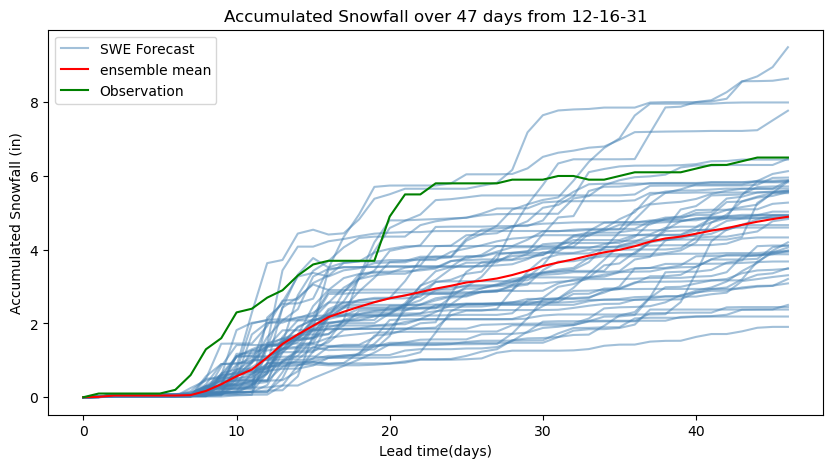

<Figure size 640x480 with 0 Axes>

In [94]:
snotel_lat = snotel_842.latitude.values #get the snotel lat and longs
snotel_lon = snotel_842.longitude.values


global_lon = snotel_lon % 360  # Result: 254.22
global_lat = snotel_lat   #global lat same -90 -> 90

#print(global_lat, global_lon)

# select the area based on the forecast
forecasted_at_station = snow_forecast['sf'].sel( 
                                                longitude = global_lon, 
                                                latitude = global_lat,
                                                method= "nearest")

# remove the inital accumulated snow from the snotel data, so its just change.
snotel_change = snotel_842['WTEQ'] - snotel_842['WTEQ'].isel(time = 0)



# dividde by 25.4 gets SWE(kg/m^2) back into SWE (in), change units in df
swe_forecast = forecasted_at_station.squeeze(drop = True) / 25.4
swe_forecast.attrs['units'] = 'in'



# mean along all the members, full ensemble mean
ensemble_mean = swe_forecast.mean(dim='number')


#return lead time, from nanoseconds to days
lead_time_days = swe_forecast.step / np.timedelta64(1, 'D')


print(f"number of forcasted days: {lead_time_days.size}") # number of days




#plot the swe and lead time, time series
fig, ax = plt.subplots(figsize = (10,5))

forecast = ax.plot(lead_time_days, swe_forecast.T,color = 'steelblue',alpha = .5)
ax.plot(lead_time_days,ensemble_mean,color='red', label = 'ensemble mean')
ax.plot(lead_time_days,snotel_change,color='g',label = 'Observation')

forecast[0].set_label('SWE Forecast')

ax.set_xlabel("Lead time(days)")
ax.set_ylabel("Accumulated Snowfall (in)")
ax.set_title("Accumulated Snowfall over 47 days from 12-16-31")


plt.legend()
plt.show()
plt.tight_layout()



## Calculating RMSE

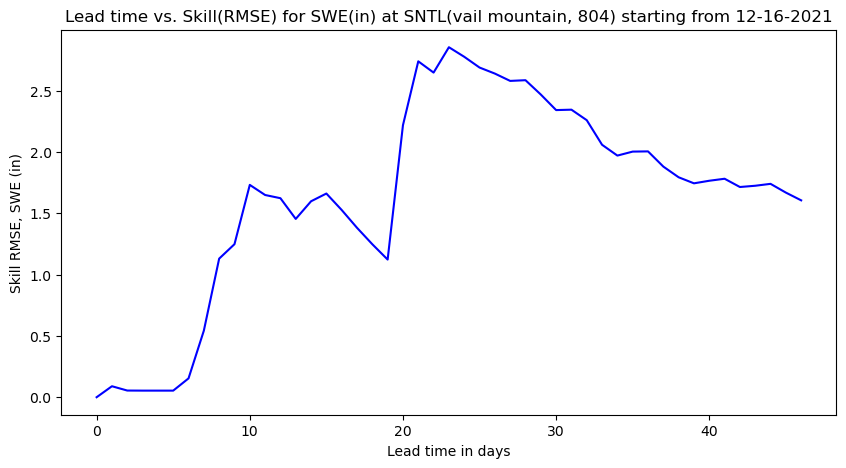

In [85]:
snotel_aligned = snotel_change.sel(time = ensemble_mean.valid_time,method='nearest')


RMSE = np.sqrt((snotel_aligned - ensemble_mean )**2)
RMSE_Members = np.sqrt((snotel_aligned - swe_forecast )**2)


fig, ax = plt.subplots(figsize = (10,5))








ax.plot(lead_time_days, RMSE, color = 'blue') #the main plot skill and lead time

ax.set_xlabel('Lead time in days')
ax.set_ylabel('Skill RMSE, SWE (in)')
ax.set_title('Lead time vs. Skill(RMSE) for SWE(in) at SNTL(vail mountain, 804) starting from 12-16-2021')

plt.tight_layout

plt.show()




